# Phân tích khám phá dữ liệu (EDA) – Dự báo nhu cầu sản phẩm M5 Walmart

Notebook này là bản viết lại của `EDA.ipynb`:

- Đọc trực tiếp dữ liệu **đã qua pipeline** (`data/processed/*.parquet`), không cần tạo file CSV 7,7 GB.
- Chạy được với **pandas 3.0** và seaborn mới (`histplot` thay cho `distplot`, `groupby(..., observed=True)`).
- So sánh theo tháng/năm bằng **doanh số trung bình mỗi ngày**, tránh sai lệch do năm 2011 và 2016 không đủ 12 tháng.
- Có so sánh phân phối **train / valid / test**.
- Mỗi phần có **Nhận xét** và **Ý nghĩa cho mô hình**.

> Đầu vào: `data/processed/sales_clean.parquet`, `train/valid/test.parquet` (do pipeline xử lý dữ liệu tạo ra) và các CSV gốc trong `data/` (chỉ dùng ở mục 10).

## 0. Thiết lập

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Tìm thư mục gốc dự án (nơi có data/processed) để notebook chạy được dù mở ở thư mục nào
ROOT = Path.cwd()
while not (ROOT / "data" / "processed").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA = ROOT / "data"
PROCESSED = DATA / "processed"

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)
print("pandas", pd.__version__, "| Thư mục dự án:", ROOT)
print("Các file đã xử lý:", sorted(p.name for p in PROCESSED.glob("*.parquet")))

pandas 3.0.6 | Thư mục dự án: C:\Users\Dell\School\DoAnChuyenNganh
Các file đã xử lý: ['features.parquet', 'sales_clean.parquet', 'test.parquet', 'train.parquet', 'valid.parquet']


## 1. Đọc dữ liệu & tổng quan

In [2]:
df = pd.read_parquet(PROCESSED / "sales_clean.parquet")
df["revenue"] = df["sales"] * df["sell_price"]
print(f"Số dòng: {len(df):,} | Số cột: {df.shape[1]} | RAM: {df.memory_usage(deep=True).sum()/1024**2:.0f} MB")
print(f"Số chuỗi (sản phẩm × cửa hàng): {df['id'].nunique():,}")
print(f"Khoảng thời gian: {df['date'].min().date()} → {df['date'].max().date()} ({df['d_num'].nunique()} ngày)")
df.head()

Số dòng: 4,788,267 | Số cột: 21 | RAM: 183 MB
Số chuỗi (sản phẩm × cửa hàng): 3,049
Khoảng thời gian: 2011-01-29 → 2016-05-22 (1941 ngày)


,id,item_id,dept_id,cat_id,store_id,state_id,sales,d_num,date,wm_yr_wk,weekday,wday,month,year,event_name_1,event_type_1,event_name_2,event_type_2,snap,sell_price,revenue
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,897,2013-07-13,11325,Saturday,1,7,2013,NoEvent,NoEvent,NoEvent,NoEvent,0,9.58,0.0
1,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,898,2013-07-14,11325,Sunday,2,7,2013,NoEvent,NoEvent,NoEvent,NoEvent,0,9.58,0.0
2,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,899,2013-07-15,11325,Monday,3,7,2013,NoEvent,NoEvent,NoEvent,NoEvent,0,9.58,0.0
3,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,900,2013-07-16,11325,Tuesday,4,7,2013,NoEvent,NoEvent,NoEvent,NoEvent,0,9.58,0.0
4,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,901,2013-07-17,11325,Wednesday,5,7,2013,NoEvent,NoEvent,NoEvent,NoEvent,0,9.58,0.0


In [3]:
df.dtypes.to_frame("dtype").T

,id,item_id,dept_id,cat_id,store_id,state_id,sales,d_num,date,wm_yr_wk,weekday,wday,month,year,event_name_1,event_type_1,event_name_2,event_type_2,snap,sell_price,revenue
dtype,category,category,category,category,category,category,int16,int16,datetime64[us],int16,category,int8,int8,int16,category,category,category,category,int8,float32,float32


In [4]:
# Kiểm tra nhanh chất lượng dữ liệu
checks = {
    "Số ô bị thiếu (NaN)": int(df.isna().sum().sum()),
    "Trùng khoá (id, d_num)": int(df.duplicated(["id", "d_num"]).sum()),
    "Doanh số âm": int((df["sales"] < 0).sum()),
    "Giá <= 0": int((df["sell_price"] <= 0).sum()),
    "Số ngày bị khuyết trong lịch": int((np.diff(np.sort(df["d_num"].unique())) != 1).sum()),
}
pd.Series(checks).to_frame("số lỗi (0 = đạt)")

,số lỗi (0 = đạt)
Số ô bị thiếu (NaN),0
"Trùng khoá (id, d_num)",0
Doanh số âm,0
Giá <= 0,0
Số ngày bị khuyết trong lịch,0


In [5]:
# Số giá trị khác nhau của các cột phân loại
df[["item_id", "dept_id", "cat_id", "store_id", "state_id", "event_name_1", "event_type_1"]].nunique().to_frame("số giá trị")

,số giá trị
item_id,3049
dept_id,7
cat_id,3
store_id,1
state_id,1
event_name_1,31
event_type_1,5


**Nhận xét**
- Dữ liệu đã được làm sạch: không trùng khoá, không thiếu giá, ngày liên tục.
- Các ngày trước khi sản phẩm lên kệ đã bị loại, nên mỗi chuỗi có độ dài khác nhau.
- Cột `wday = 1` tương ứng **thứ Bảy** (tuần Walmart bắt đầu từ thứ Bảy); pipeline tạo thêm `day_of_week` (0 = thứ Hai) cho dễ hiểu.

## 2. Phân phối biến mục tiêu `sales` – dữ liệu rất nhiều số 0

Tỷ lệ ngày bán 0: 55.2%
count    4788267.00
mean           1.64
std            4.45
min            0.00
50%            0.00
75%            2.00
90%            4.00
99%           19.00
max          648.00


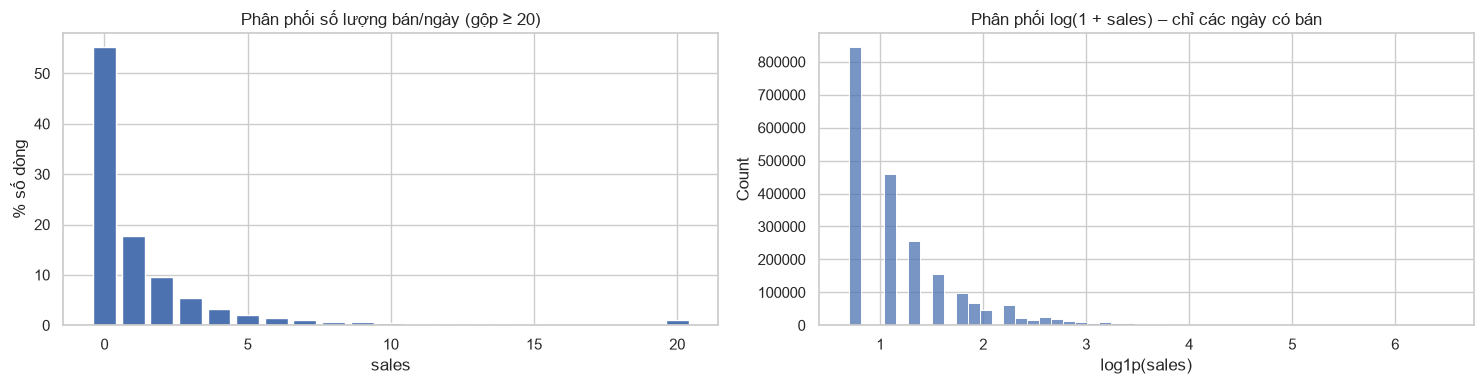

In [6]:
zero_ratio = (df["sales"] == 0).mean()
print(f"Tỷ lệ ngày bán 0: {zero_ratio:.1%}")
print(df["sales"].describe(percentiles=[.5, .75, .9, .99]).round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
vc = df["sales"].clip(upper=20).value_counts().sort_index()
axes[0].bar(vc.index, vc.values / len(df) * 100)
axes[0].set(title="Phân phối số lượng bán/ngày (gộp ≥ 20)", xlabel="sales", ylabel="% số dòng")
sns.histplot(np.log1p(df.loc[df["sales"] > 0, "sales"]), bins=50, ax=axes[1])
axes[1].set(title="Phân phối log(1 + sales) – chỉ các ngày có bán", xlabel="log1p(sales)")
plt.tight_layout(); plt.show()

### Phân loại chuỗi theo kiểu nhu cầu (Syntetos–Boylan)
- **ADI** (khoảng cách trung bình giữa 2 lần có bán) và **CV²** (độ biến động của lượng bán khi có bán).
- 4 nhóm: *Smooth* (đều), *Erratic* (thất thường), *Intermittent* (gián đoạn), *Lumpy* (gián đoạn + thất thường).

type
Intermittent    72.0
Lumpy           17.9
Smooth           7.6
Erratic          2.5


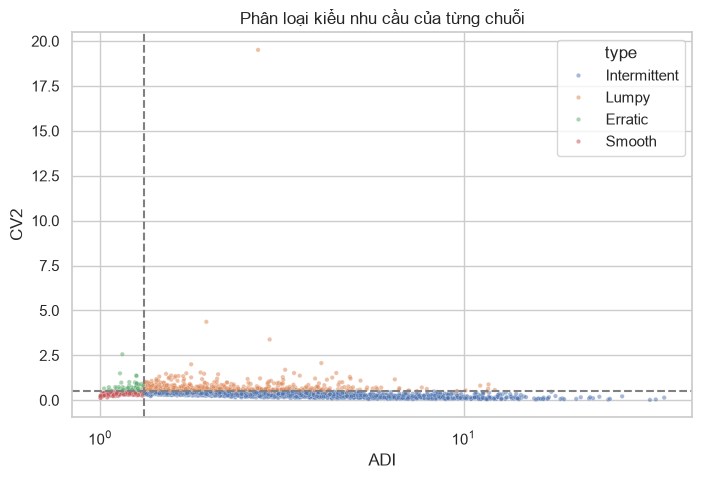

In [7]:
g = df.groupby("id", observed=True)["sales"]
stats = pd.DataFrame({
    "n_days": g.size(),
    "n_nonzero": g.apply(lambda s: (s > 0).sum()),
    "mean_nonzero": g.apply(lambda s: s[s > 0].mean()),
    "std_nonzero": g.apply(lambda s: s[s > 0].std()),
})
stats["ADI"] = stats["n_days"] / stats["n_nonzero"].replace(0, np.nan)
stats["CV2"] = (stats["std_nonzero"] / stats["mean_nonzero"]) ** 2

def demand_type(r):
    if pd.isna(r.ADI):
        return "Không bán"
    if r.ADI < 1.32:
        return "Smooth" if r.CV2 < 0.49 else "Erratic"
    return "Intermittent" if r.CV2 < 0.49 else "Lumpy"

stats["type"] = stats.apply(demand_type, axis=1)
type_share = stats["type"].value_counts(normalize=True).mul(100).round(1)
print(type_share.to_string())

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=stats, x="ADI", y="CV2", hue="type", s=10, alpha=.5, ax=ax)
ax.axvline(1.32, ls="--", c="gray"); ax.axhline(0.49, ls="--", c="gray")
ax.set(xscale="log", title="Phân loại kiểu nhu cầu của từng chuỗi")
plt.show()

**Nhận xét**
- Phần lớn các ngày có doanh số = 0, và đa số chuỗi thuộc nhóm **Intermittent/Lumpy** (bán gián đoạn).
- Phân phối lệch phải mạnh: vài ngày bán rất nhiều.

**Ý nghĩa cho mô hình**
- RMSE thường sẽ "thưởng" cho mô hình đoán toàn 0 → dùng **WRMSSE / RMSSE** để đánh giá.
- Nên dùng hàm mất mát **Tweedie hoặc Poisson** (LightGBM `objective="tweedie"`), phù hợp dữ liệu đếm nhiều số 0.
- Đặc trưng `nonzero_ratio_28` (tỷ lệ ngày có bán) giúp mô hình phân biệt chuỗi thưa và chuỗi đều.

## 3. Doanh số theo nhóm hàng và ngành hàng

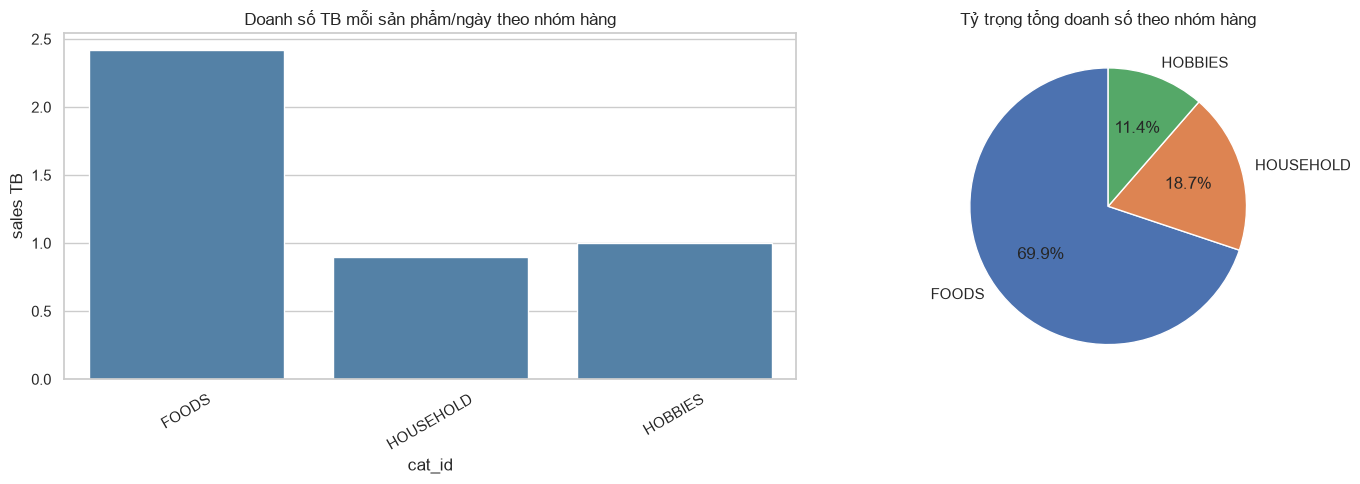

,mean,sum
cat_id,,
FOODS,2.42,5471661
HOUSEHOLD,0.90,1468504
HOBBIES,1.00,892083


In [8]:
def bar_and_pie(col, title):
    # Trung bình mỗi dòng (sản phẩm-ngày) và tỷ trọng tổng doanh số
    agg = df.groupby(col, observed=True)["sales"].agg(["mean", "sum"]).sort_values("sum", ascending=False)
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    sns.barplot(x=agg.index.astype(str), y=agg["mean"], ax=axes[0], color="steelblue")
    axes[0].set(title=f"Doanh số TB mỗi sản phẩm/ngày theo {title}", xlabel=col, ylabel="sales TB")
    axes[0].tick_params(axis="x", rotation=30)
    axes[1].pie(agg["sum"], labels=agg.index.astype(str), autopct="%1.1f%%", startangle=90)
    axes[1].set_title(f"Tỷ trọng tổng doanh số theo {title}")
    plt.tight_layout(); plt.show()
    return agg

bar_and_pie("cat_id", "nhóm hàng").round(2)

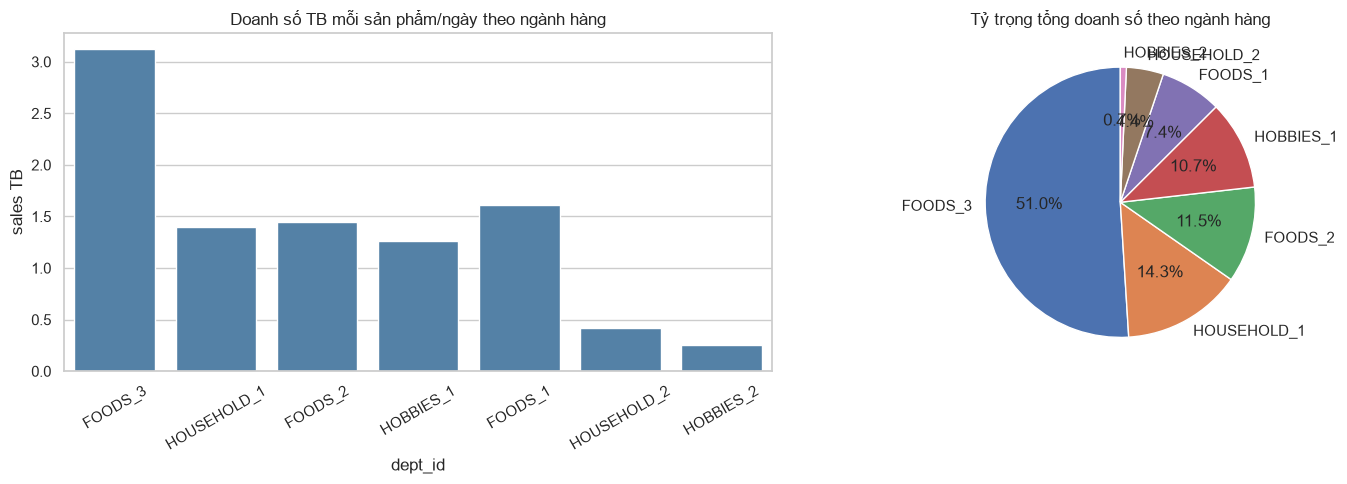

,mean,sum
dept_id,,
FOODS_3,3.12,3993834
HOUSEHOLD_1,1.40,1121388
FOODS_2,1.45,900391
HOBBIES_1,1.26,835578
FOODS_1,1.61,577436
HOUSEHOLD_2,0.41,347116
HOBBIES_2,0.25,56505


In [9]:
bar_and_pie("dept_id", "ngành hàng").round(2)

**Nhận xét**
- **FOODS** chiếm phần lớn doanh số; riêng **FOODS_3** gần một nửa.
- HOBBIES_2 bán ít nhất.

**Ý nghĩa cho mô hình**: `cat_id`, `dept_id` là đặc trưng phân loại quan trọng; có thể cân nhắc huấn luyện **mô hình riêng cho từng nhóm hàng**.

## 4. Xu hướng theo thời gian
Tổng doanh số mỗi ngày của tất cả sản phẩm, kèm đường trung bình trượt 28 ngày.

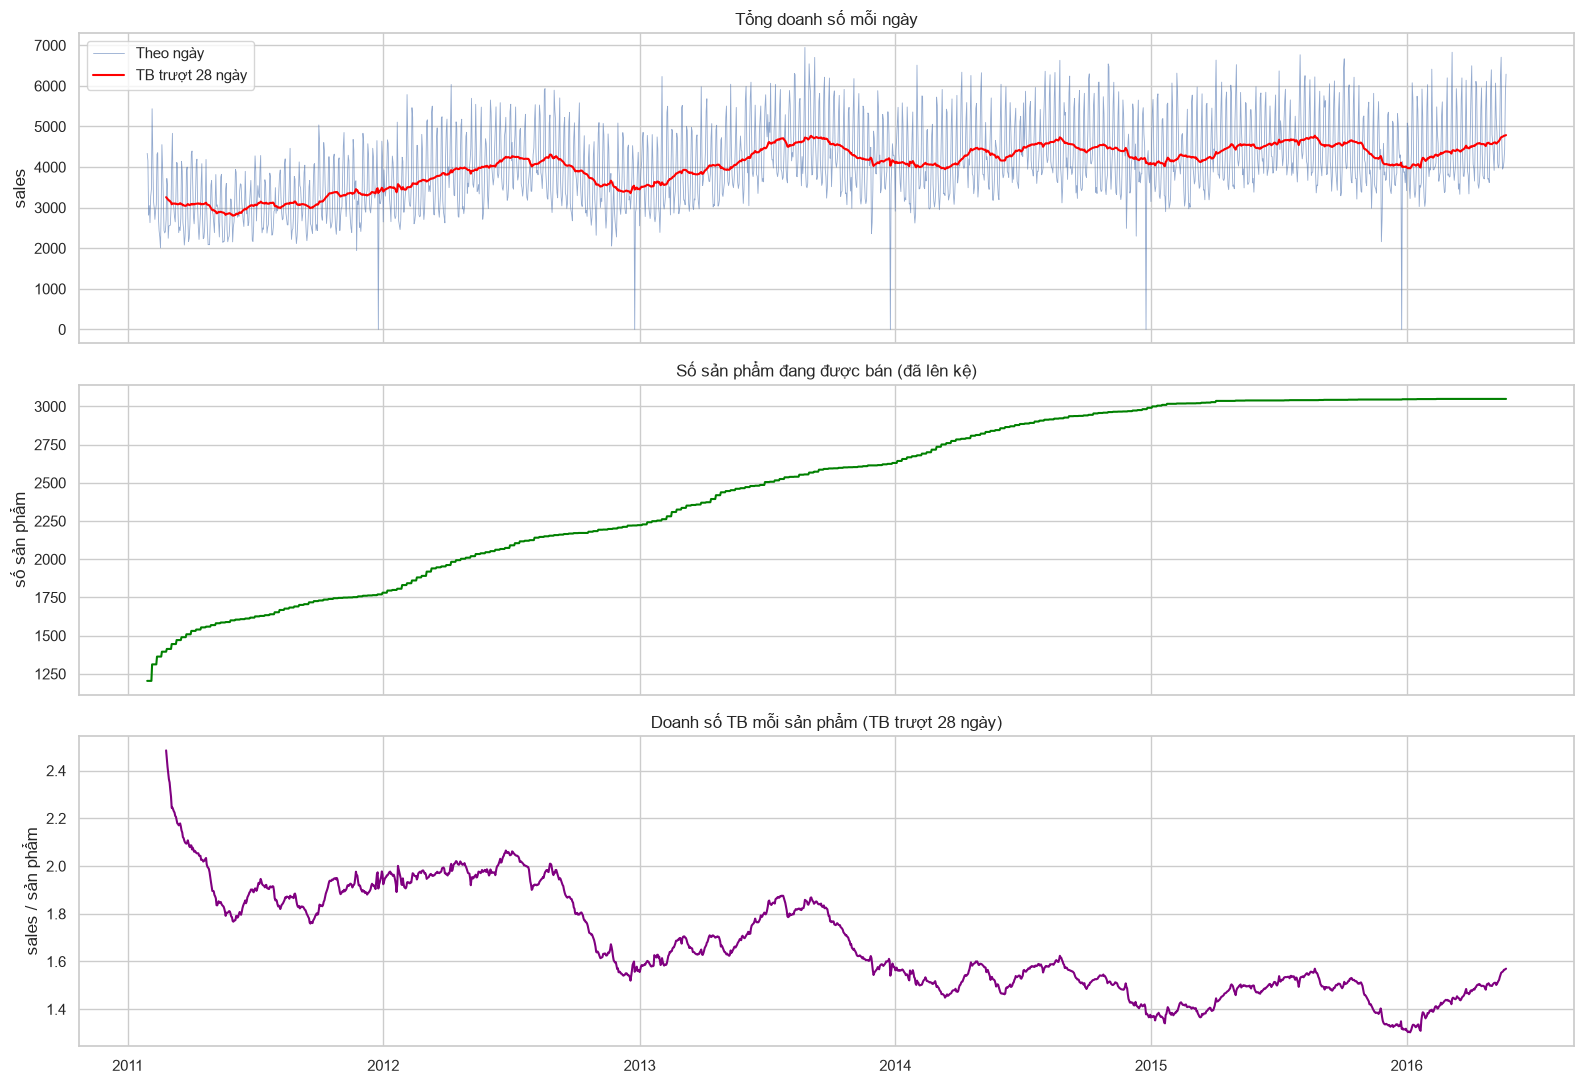

Các ngày doanh số thấp bất thường:


,sales,n_items
date,,
2011-12-25,0,1770
2012-12-25,0,2221
2013-12-25,0,2624
2014-12-25,0,2982
2015-12-25,0,3045
2011-11-24,1941,1752


In [10]:
daily = df.groupby("date").agg(sales=("sales", "sum"), n_items=("id", "nunique"), revenue=("revenue", "sum"))
daily["sales_per_item"] = daily["sales"] / daily["n_items"]

fig, axes = plt.subplots(3, 1, figsize=(16, 11), sharex=True)
axes[0].plot(daily.index, daily["sales"], lw=.6, alpha=.6, label="Theo ngày")
axes[0].plot(daily.index, daily["sales"].rolling(28).mean(), c="red", label="TB trượt 28 ngày")
axes[0].set(title="Tổng doanh số mỗi ngày", ylabel="sales"); axes[0].legend()
axes[1].plot(daily.index, daily["n_items"], c="green")
axes[1].set(title="Số sản phẩm đang được bán (đã lên kệ)", ylabel="số sản phẩm")
axes[2].plot(daily.index, daily["sales_per_item"].rolling(28).mean(), c="purple")
axes[2].set(title="Doanh số TB mỗi sản phẩm (TB trượt 28 ngày)", ylabel="sales / sản phẩm")
plt.tight_layout(); plt.show()

print("Các ngày doanh số thấp bất thường:")
daily.nsmallest(6, "sales")[["sales", "n_items"]]

**Nhận xét**
- Tổng doanh số có **xu hướng tăng**, một phần do **số sản phẩm được bán tăng dần** theo thời gian.
- Các ngày doanh số gần bằng 0 là **ngày Giáng sinh (25/12)** – cửa hàng đóng cửa.

**Ý nghĩa cho mô hình**
- Cần đặc trưng xu hướng: lag, rolling mean (`lag_28`, `roll_mean_28`...).
- Ngày 25/12 là ngoại lệ, có thể loại khỏi tập train hoặc đánh dấu riêng.

## 5. Tính mùa vụ: thứ trong tuần, tháng, năm
> Khác `EDA.ipynb` gốc: dùng **tổng doanh số trung bình mỗi ngày** để so sánh, vì năm 2011 bắt đầu từ 29/1 và 2016 chỉ có đến tháng 5 –
> so sánh tổng doanh số theo tháng/năm sẽ bị lệch do số ngày khác nhau.

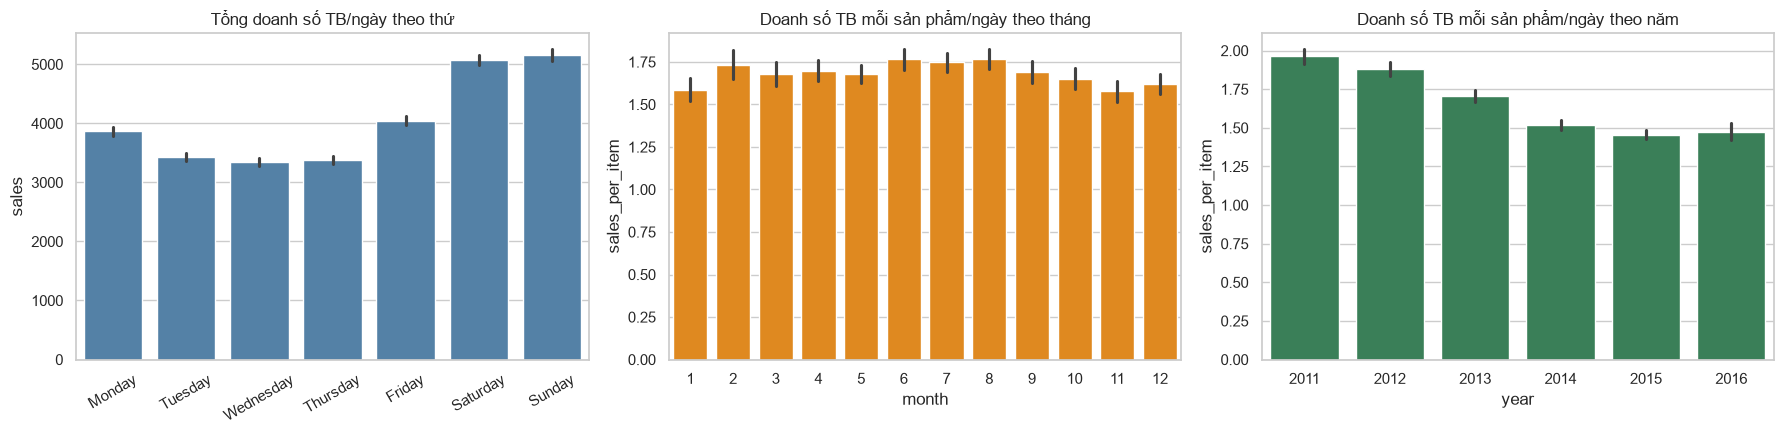

Cuối tuần (T7+CN) bán nhiều hơn ngày thường 41.7%


In [11]:
daily_cal = daily.reset_index()
daily_cal["day_of_week"] = daily_cal["date"].dt.day_name()
daily_cal["month"] = daily_cal["date"].dt.month
daily_cal["year"] = daily_cal["date"].dt.year
daily_cal = daily_cal[~((daily_cal["date"].dt.month == 12) & (daily_cal["date"].dt.day == 25))]  # bỏ Giáng sinh

order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.barplot(data=daily_cal, x="day_of_week", y="sales", order=order, ax=axes[0], color="steelblue")
axes[0].set(title="Tổng doanh số TB/ngày theo thứ", xlabel=""); axes[0].tick_params(axis="x", rotation=30)
sns.barplot(data=daily_cal, x="month", y="sales_per_item", ax=axes[1], color="darkorange")
axes[1].set(title="Doanh số TB mỗi sản phẩm/ngày theo tháng")
sns.barplot(data=daily_cal, x="year", y="sales_per_item", ax=axes[2], color="seagreen")
axes[2].set(title="Doanh số TB mỗi sản phẩm/ngày theo năm")
plt.tight_layout(); plt.show()

dow = daily_cal.groupby("day_of_week")["sales"].mean().reindex(order)
print(f"Cuối tuần (T7+CN) bán nhiều hơn ngày thường {(dow[['Saturday','Sunday']].mean()/dow[order[:5]].mean()-1):.1%}")

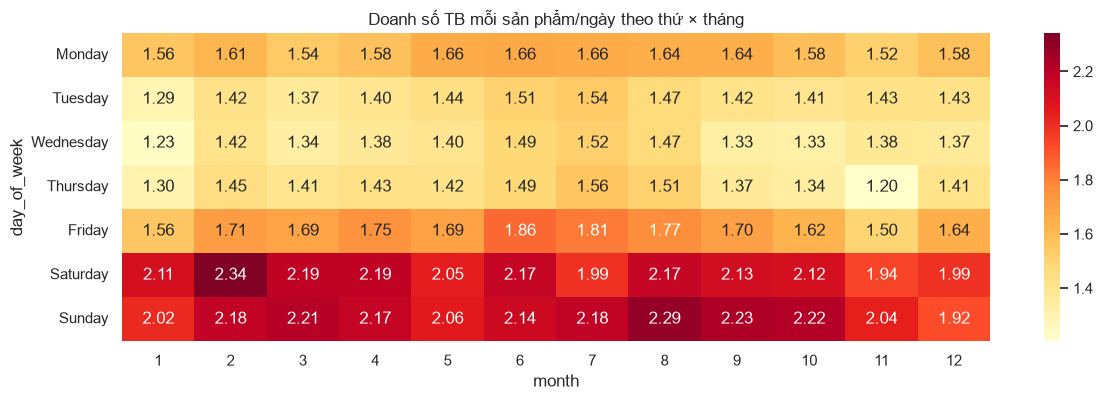

In [12]:
# Heatmap: thứ × tháng
pivot = daily_cal.pivot_table(index="day_of_week", columns="month", values="sales_per_item", aggfunc="mean").reindex(order)
plt.figure(figsize=(14, 4))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlOrRd")
plt.title("Doanh số TB mỗi sản phẩm/ngày theo thứ × tháng"); plt.show()

**Nhận xét**
- **Thứ Bảy, Chủ nhật bán nhiều nhất** – tính mùa vụ theo tuần rất rõ.
- Theo tháng, chênh lệch nhỏ hơn nhiều so với theo tuần: mùa hè (tháng 6–8) cao hơn một chút, tháng 1 và 11 thấp nhất.
  (Khác `EDA.ipynb` gốc kết luận "tháng 2 cao nhất" – do gốc dùng trung bình mỗi dòng, bị ảnh hưởng bởi số sản phẩm thay đổi.)
- Theo năm: doanh số **mỗi sản phẩm giảm dần** từ 2011 đến 2015 dù tổng doanh số tăng → tăng trưởng đến từ việc **có thêm sản phẩm mới**,
  và các sản phẩm mới thường bán ít hơn sản phẩm cũ. Đây là lý do `EDA.ipynb` gốc thấy "năm 2011 có trung bình cao nhất".

**Ý nghĩa cho mô hình**: dùng `day_of_week`, `is_weekend`, `month`, `dow_mean_4w` (TB theo thứ của 4 tuần trước).

## 6. Ảnh hưởng của SNAP và sự kiện/ngày lễ

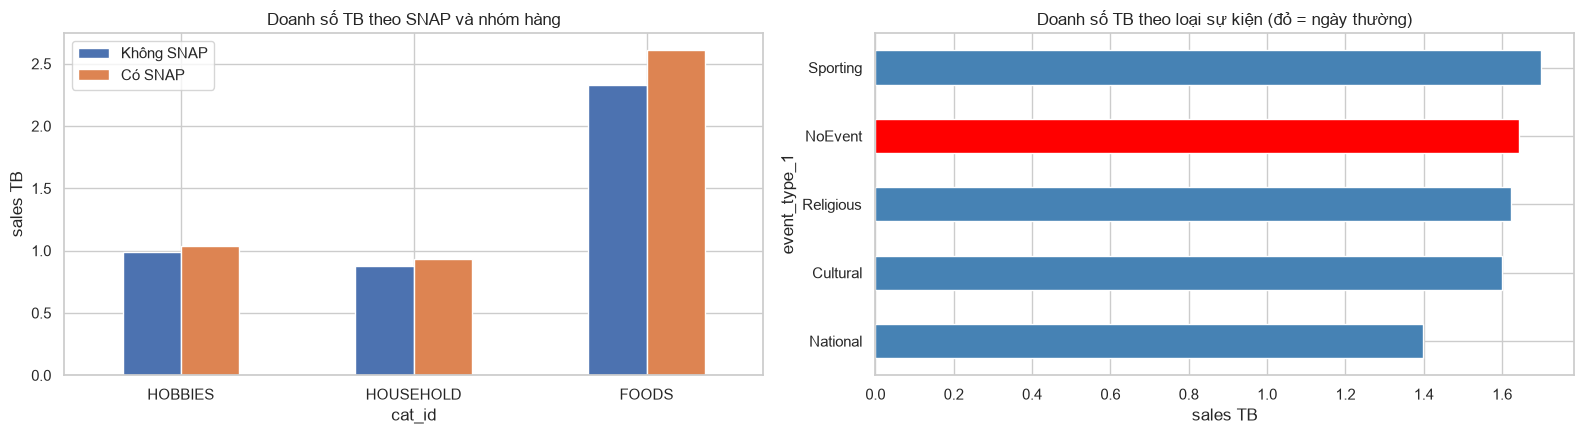

Mức tăng doanh số ngày SNAP so với ngày thường (%):
cat_id
HOBBIES       5.0
HOUSEHOLD     5.6
FOODS        12.3


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

snap = df.groupby(["cat_id", "snap"], observed=True)["sales"].mean().unstack()
snap.plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Doanh số TB theo SNAP và nhóm hàng", ylabel="sales TB")
axes[0].legend(["Không SNAP", "Có SNAP"])

ev = df.groupby("event_type_1", observed=True)["sales"].mean().sort_values()
ev.plot.barh(ax=axes[1], color=["red" if i == "NoEvent" else "steelblue" for i in ev.index])
axes[1].set(title="Doanh số TB theo loại sự kiện (đỏ = ngày thường)", xlabel="sales TB")
plt.tight_layout(); plt.show()

print("Mức tăng doanh số ngày SNAP so với ngày thường (%):")
print(((snap[1] / snap[0] - 1) * 100).round(1).to_string())

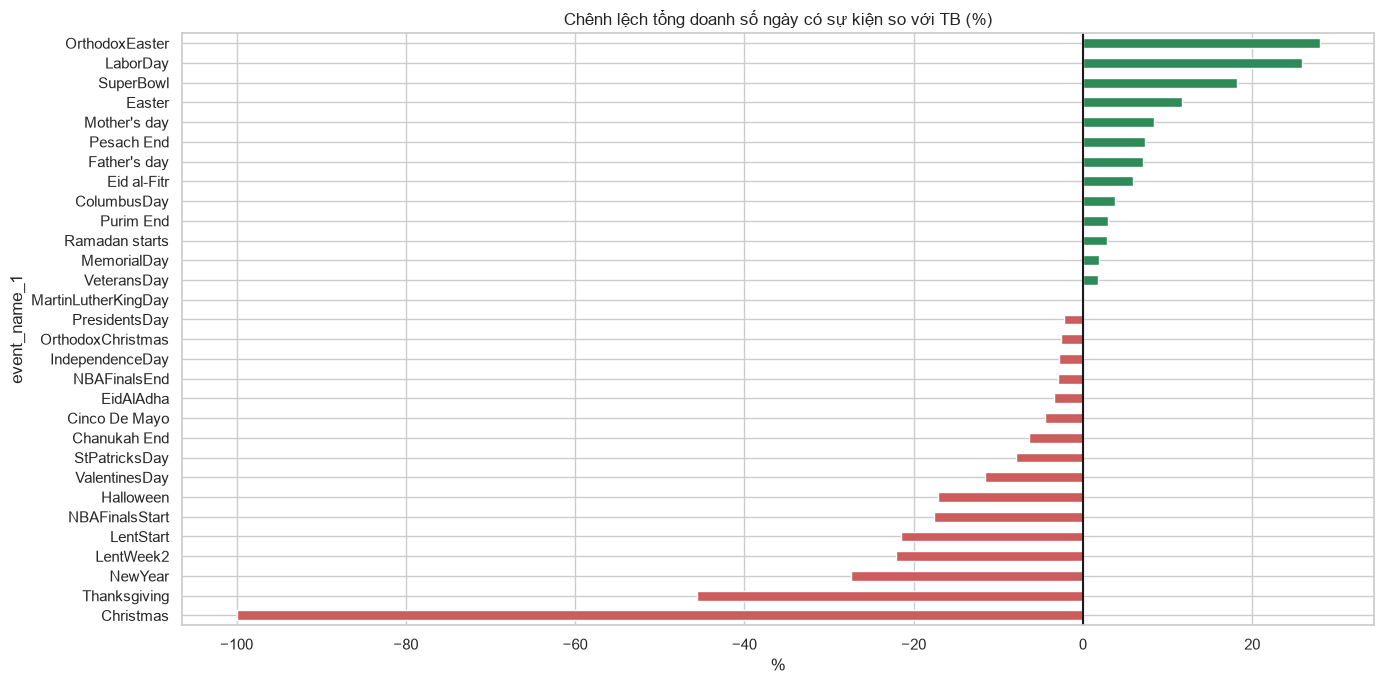

In [14]:
# Các sự kiện cụ thể làm tăng/giảm doanh số nhiều nhất (so với TB ngày không có sự kiện)
base = daily_cal.loc[:, "sales"].mean()
ev_daily = df.groupby(["date", "event_name_1"], observed=True)["sales"].sum().reset_index()
ev_effect = (ev_daily[ev_daily["event_name_1"] != "NoEvent"]
             .groupby("event_name_1", observed=True)["sales"].mean().div(base).sub(1).mul(100).sort_values())
plt.figure(figsize=(14, 7))
ev_effect.plot.barh(color=np.where(ev_effect > 0, "seagreen", "indianred"))
plt.axvline(0, c="k"); plt.title("Chênh lệch tổng doanh số ngày có sự kiện so với TB (%)"); plt.xlabel("%")
plt.tight_layout(); plt.show()

**Nhận xét**
- **SNAP** (tem phiếu thực phẩm) làm tăng doanh số chủ yếu ở nhóm **FOODS** – đúng với bản chất chương trình.
- Sự kiện có tác động **khác nhau**: có ngày lễ làm tăng (OrthodoxEaster, LaborDay, SuperBowl: +18–28%), có ngày làm giảm mạnh (Christmas –100%, Thanksgiving –45%, NewYear –27%).

**Ý nghĩa cho mô hình**: giữ `snap` (theo đúng bang), `event_name_1`, `event_type_1`, `has_event`;
có thể thêm đặc trưng "số ngày trước/sau sự kiện".

## 7. Giá bán và ảnh hưởng của giá

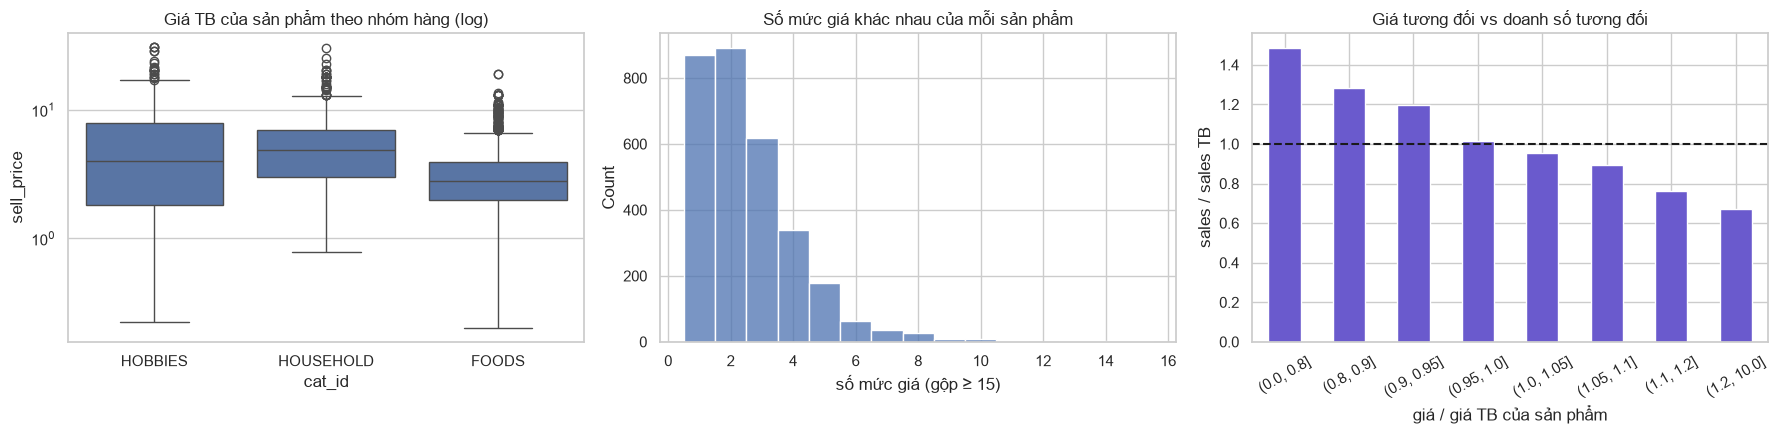

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
item_price = df.groupby(["item_id", "cat_id"], observed=True)["sell_price"].mean().reset_index()
sns.boxplot(data=item_price, x="cat_id", y="sell_price", ax=axes[0])
axes[0].set(yscale="log", title="Giá TB của sản phẩm theo nhóm hàng (log)")

n_changes = df.groupby("id", observed=True)["sell_price"].nunique()
sns.histplot(n_changes.clip(upper=15), discrete=True, ax=axes[1])
axes[1].set(title="Số mức giá khác nhau của mỗi sản phẩm", xlabel="số mức giá (gộp ≥ 15)")

# Giá tương đối so với giá TB của chính sản phẩm đó -> doanh số tương đối
tmp = df[["id", "sell_price", "sales"]].copy()
tmp["price_rel"] = tmp["sell_price"] / tmp.groupby("id", observed=True)["sell_price"].transform("mean")
tmp["sales_rel"] = tmp["sales"] / tmp.groupby("id", observed=True)["sales"].transform("mean").replace(0, np.nan)
tmp["bin"] = pd.cut(tmp["price_rel"], [0, .8, .9, .95, 1.0, 1.05, 1.1, 1.2, 10])
el = tmp.groupby("bin", observed=True)["sales_rel"].mean()
el.plot.bar(ax=axes[2], rot=30, color="slateblue")
axes[2].axhline(1, c="k", ls="--")
axes[2].set(title="Giá tương đối vs doanh số tương đối", xlabel="giá / giá TB của sản phẩm", ylabel="sales / sales TB")
plt.tight_layout(); plt.show()

**Nhận xét**
- HOUSEHOLD và HOBBIES có giá cao, FOODS rẻ hơn.
- Giá mỗi sản phẩm thay đổi vài lần trong 5 năm.
- Khi giá **thấp hơn** mức TB của chính sản phẩm (khuyến mãi), doanh số **tăng** – có độ co giãn theo giá.

**Ý nghĩa cho mô hình**: dùng giá **tương đối** thay vì giá tuyệt đối: `price_norm`, `price_rel_mean`, `price_change_w`, `price_rel_dept`.

## 8. Tự tương quan (autocorrelation)
Đo mức độ doanh số hôm nay giống doanh số *k* ngày trước – cơ sở để chọn lag.

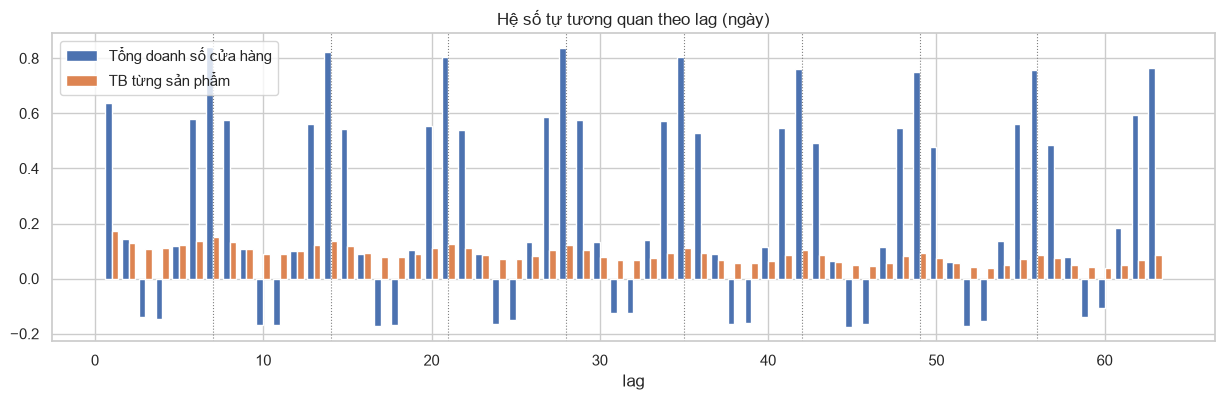

In [16]:
s = daily_cal.set_index("date")["sales"]
lags = range(1, 64)
acf_total = [s.autocorr(l) for l in lags]

# Tự tương quan trung bình trên từng chuỗi (lấy mẫu 300 chuỗi cho nhanh)
sample_ids = df["id"].drop_duplicates().sample(300, random_state=42)
sub = df[df["id"].isin(sample_ids)]
acf_item = [sub.groupby("id", observed=True)["sales"].apply(lambda x: x.autocorr(l)).mean() for l in lags]

fig, ax = plt.subplots(figsize=(15, 4))
ax.bar(np.array(list(lags)) - .2, acf_total, width=.4, label="Tổng doanh số cửa hàng")
ax.bar(np.array(list(lags)) + .2, acf_item, width=.4, label="TB từng sản phẩm")
for l in (7, 14, 21, 28, 35, 42, 49, 56):
    ax.axvline(l, c="gray", ls=":", lw=.8)
ax.set(title="Hệ số tự tương quan theo lag (ngày)", xlabel="lag"); ax.legend()
plt.show()

**Nhận xét**
- Tổng doanh số có **đỉnh tự tương quan tại các bội số của 7** (7, 14, 21, 28...) → chu kỳ tuần.
- Ở mức từng sản phẩm, tự tương quan thấp hơn (nhiễu lớn, nhiều số 0) nhưng vẫn còn đáng kể ở lag 28+.

**Ý nghĩa cho mô hình**: pipeline dùng lag **28, 35, 42, 49, 56** – đều là bội số của 7 và ≥ 28 (độ dài dự báo)
nên vừa giữ được chu kỳ tuần, vừa **không rò rỉ dữ liệu tương lai**.

## 9. So sánh train / valid / test
> `EDA.ipynb` gốc kết luận "train và test cùng phân phối" nhưng không có biểu đồ kiểm chứng – phần này bổ sung.

In [17]:
cols = ["sales", "d_num", "date", "cat_id", "sell_price", "has_event", "snap"]
parts = {name: pd.read_parquet(PROCESSED / f"{name}.parquet", columns=cols) for name in ["train", "valid", "test"]}
summary = pd.DataFrame({
    name: {
        "từ ngày": p["date"].min().date(), "đến ngày": p["date"].max().date(), "số dòng": len(p),
        "sales TB": round(p["sales"].mean(), 3), "tỷ lệ bán 0": round((p["sales"] == 0).mean(), 3),
        "giá TB": round(p["sell_price"].mean(), 2), "tỷ lệ ngày SNAP": round(p["snap"].mean(), 3),
        "tỷ lệ ngày sự kiện": round(p["has_event"].mean(), 3),
    } for name, p in parts.items()
})
summary

,train,valid,test
từ ngày,2011-02-26,2016-03-28,2016-04-25
đến ngày,2016-03-27,2016-04-24,2016-05-22
số dòng,4532151,85372,85372
sales TB,1.638,1.499,1.57
tỷ lệ bán 0,0.554,0.533,0.509
giá TB,4.41,4.49,4.49
tỷ lệ ngày SNAP,0.328,0.357,0.357
tỷ lệ ngày sự kiện,0.081,0.0,0.143


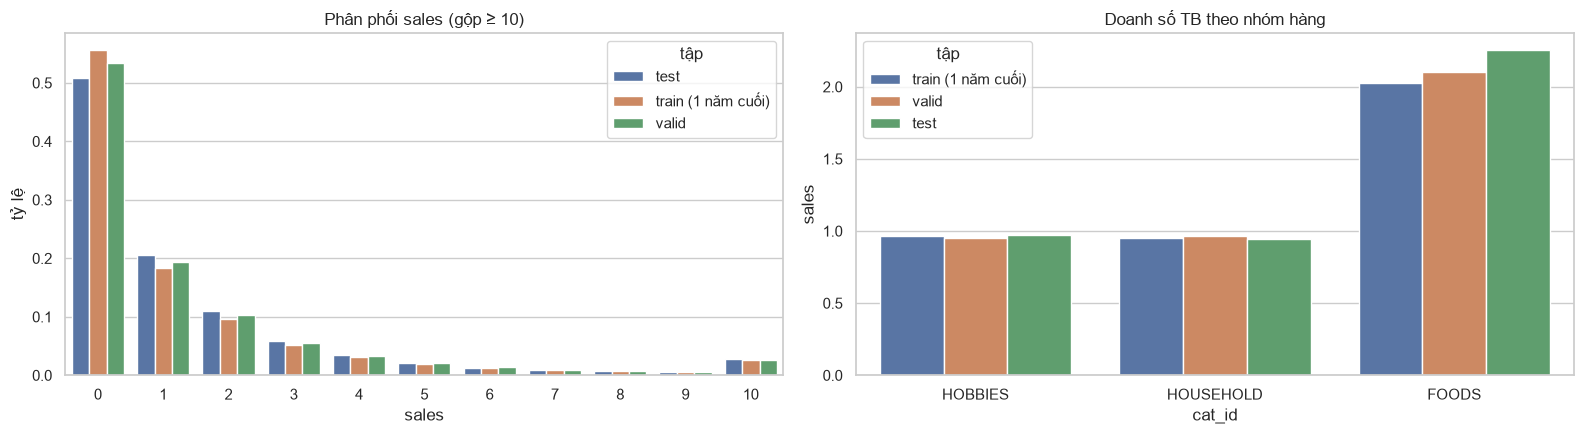

In [18]:
recent = parts["train"][parts["train"]["d_num"] > parts["train"]["d_num"].max() - 365]  # 1 năm cuối của train
cmp = pd.concat([recent.assign(tập="train (1 năm cuối)"), parts["valid"].assign(tập="valid"), parts["test"].assign(tập="test")])

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
dist = cmp.assign(sales=cmp["sales"].clip(upper=10)).groupby("tập")["sales"].value_counts(normalize=True).rename("tỷ lệ").reset_index()
sns.barplot(data=dist, x="sales", y="tỷ lệ", hue="tập", ax=axes[0])
axes[0].set(title="Phân phối sales (gộp ≥ 10)")
sns.barplot(data=cmp, x="cat_id", y="sales", hue="tập", ax=axes[1], errorbar=None)
axes[1].set(title="Doanh số TB theo nhóm hàng")
plt.tight_layout(); plt.show()

**Nhận xét**: valid và test có phân phối **gần giống** năm cuối của train (tỷ lệ số 0, mức bán TB theo nhóm hàng),
nên đánh giá mô hình trên valid/test là đáng tin cậy. Cần so sánh với *năm cuối* thay vì toàn bộ train vì doanh số tăng theo thời gian.

**Ý nghĩa MLOps**: các thống kê trong bảng trên có thể làm **mốc tham chiếu (baseline) để giám sát data drift**
khi hệ thống chạy thực tế – nếu dữ liệu mới lệch nhiều so với mốc này thì cần huấn luyện lại mô hình.

## 10. So sánh giữa các cửa hàng và bang
Dữ liệu đã qua pipeline chỉ chứa các cửa hàng đã được lọc (mặc định `CA_1`). Để so sánh **toàn bộ 10 cửa hàng**, phần này đọc
file CSV gốc nhưng chỉ tính tổng theo cửa hàng (nhẹ, không cần `melt` toàn bộ).

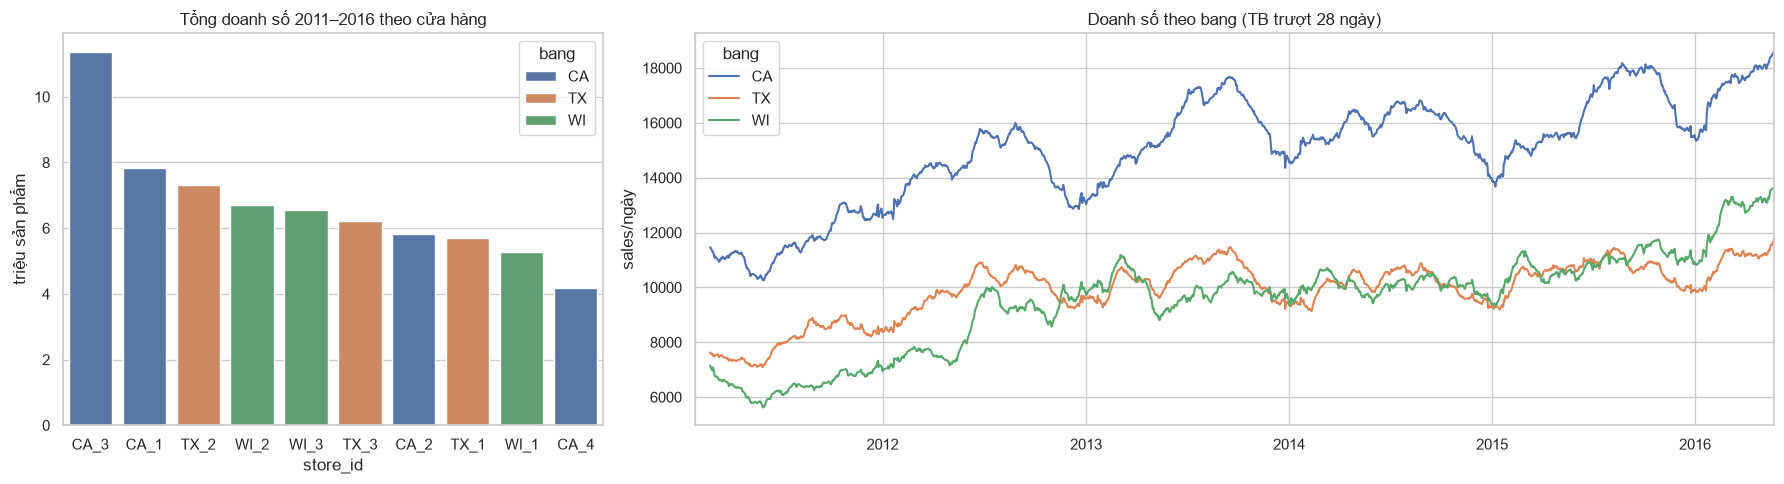

,% doanh số
store_id,
CA_3,17.0
CA_1,11.7
TX_2,11.0
WI_2,10.0
WI_3,9.8
TX_3,9.3
CA_2,8.7
TX_1,8.5
WI_1,7.9


In [19]:
raw_sales = pd.read_csv(DATA / "sales_train_evaluation.csv")
cal = pd.read_csv(DATA / "calendar.csv", parse_dates=["date"])
day_cols = [c for c in raw_sales.columns if c.startswith("d_")]

store_daily = raw_sales.groupby("store_id")[day_cols].sum().T
store_daily.index = pd.to_datetime(cal.set_index("d").loc[store_daily.index, "date"].values)
del raw_sales

fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [1, 2]})
totals = store_daily.sum().sort_values(ascending=False)
sns.barplot(x=totals.index, y=totals.values / 1e6, ax=axes[0], hue=pd.Index(totals.index.str[:2], name="bang"), dodge=False)
axes[0].set(title="Tổng doanh số 2011–2016 theo cửa hàng", ylabel="triệu sản phẩm")
state_daily = store_daily.T.groupby(store_daily.columns.str[:2]).sum().T
state_daily.rolling(28).mean().plot(ax=axes[1]); axes[1].legend(title="bang")
axes[1].set(title="Doanh số theo bang (TB trượt 28 ngày)", ylabel="sales/ngày")
plt.tight_layout(); plt.show()
(totals / totals.sum() * 100).round(1).to_frame("% doanh số")

**Nhận xét**
- **CA** là bang lớn nhất (4 cửa hàng), **CA_3** là cửa hàng bán nhiều nhất, CA_4 ít nhất.
- Mỗi bang có xu hướng riêng: WI tăng mạnh từ giữa 2012 và đầu 2016, vượt TX; CA có tính mùa vụ theo năm rõ nhất (giảm vào cuối năm).

**Ý nghĩa cho mô hình**: `store_id`, `state_id` là đặc trưng quan trọng; khi mở rộng phạm vi dữ liệu có thể huấn luyện **mô hình riêng theo cửa hàng**.

## 11. Tổng kết: từ EDA đến đặc trưng của pipeline

| Phát hiện từ EDA | Đặc trưng / quyết định trong pipeline |
|---|---|
| Rất nhiều ngày bán 0, chuỗi gián đoạn | Đánh giá bằng WRMSSE/RMSSE; loss Tweedie/Poisson; `nonzero_ratio_28` |
| Chu kỳ tuần mạnh (cuối tuần bán nhiều) | `day_of_week`, `is_weekend`, `dow_mean_4w`; lag là bội số của 7 |
| Xu hướng tăng theo thời gian | `lag_28..56`, `roll_mean_*`, `roll_std_*`; so sánh với năm gần nhất |
| SNAP làm tăng doanh số FOODS | `snap` (theo đúng bang) |
| Sự kiện/ngày lễ tác động khác nhau | `event_name_1`, `event_type_1`, `has_event` |
| Giá giảm → bán nhiều hơn | `price_norm`, `price_rel_mean`, `price_change_w`, `price_rel_dept` |
| Khác biệt lớn giữa nhóm hàng, cửa hàng | Biến phân loại `cat_id`, `dept_id`, `store_id`, `item_id` |
| Sản phẩm lên kệ ở các thời điểm khác nhau | Bỏ ngày trước khi phát hành (`drop_before_release`) |
| Ngày Giáng sinh doanh số ≈ 0 | Ngoại lệ – cân nhắc loại khỏi train |
| Valid/test giống năm cuối của train | Dùng làm baseline giám sát data drift (MLOps) |